In [1]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os
import pandas as pd

In [2]:
def read_files(glob_pattern, minyear=0, maxyear=999):
    files = glob.glob(glob_pattern)
    times = []
    peaklats_n = []
    peaklats_s = []
    
    for fpath in tqdm(files):
        year = int(os.path.basename(fpath)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue

        times.append(pd.to_datetime(os.path.basename(fpath)[:-4]))
        hdf = h5py.File(fpath)
        peaklats_n.append(hdf['peak_lat_north'][()].item())
        peaklats_s.append(hdf['peak_lat_south'][()].item())
        hdf.close()
    
    return times, np.array(peaklats_n), np.array(peaklats_s)

In [3]:
times_samples, peaklat_north_samples, peaklat_south_samples = read_files(
    '../data/validation/peaklat_samples/*.hdf5',
    maxyear=2017
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 835/835 [00:00<00:00, 1642.32it/s]


In [4]:
times_testdata, peaklat_north_testdata, peaklat_south_testdata = read_files(
    '../data/validation/peaklat_testdata/*.hdf5',
    maxyear=2017
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 835/835 [00:00<00:00, 1841.19it/s]


Text(0.5, 0.98, 'Latitudes of Peak Magnetic Field Strength at 1 $R_\\odot$')

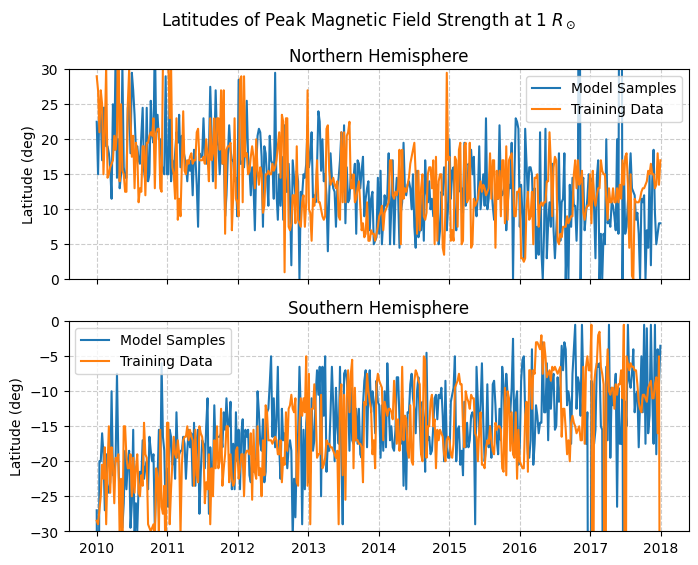

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axes[0].plot(times_samples, peaklat_north_samples, label='Model Samples')
axes[0].plot(times_samples, peaklat_north_testdata, label='Training Data')
axes[0].set_ylim(0, 30)
axes[0].legend()
axes[0].set_ylabel('Latitude (deg)')
axes[0].grid(linestyle='dashed', color='#ccc')
axes[0].set_title('Northern Hemisphere')

axes[1].plot(times_samples, peaklat_south_samples, label='Model Samples')
axes[1].plot(times_samples, peaklat_south_testdata, label='Training Data')
axes[1].set_ylim(-30, 0)
axes[1].legend(loc='upper left')
axes[1].set_ylabel('Latitude (deg)')
axes[1].grid(linestyle='dashed', color='#ccc')
axes[1].set_title('Southern Hemisphere')


fig.suptitle(r'Latitudes of Peak Magnetic Field Strength at 1 $R_\odot$')

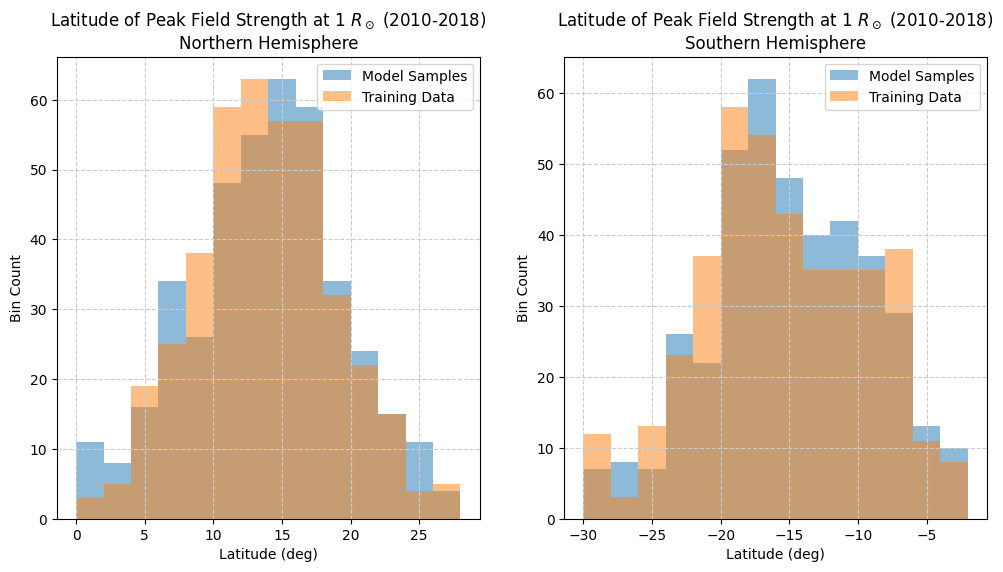

In [13]:
plt.figure(figsize=(12, 6))

plt.subplot(121)
bins = np.arange(0, 30, 2)
plt.hist(peaklat_north_samples, bins=bins, label='Model Samples', alpha=0.5)
plt.hist(peaklat_north_testdata, bins=bins, label='Training Data', alpha=0.5)
plt.legend()
plt.title(r'Latitude of Peak Field Strength at 1 $R_\odot$ (2010-2018)' + '\nNorthern Hemisphere')
plt.ylabel('Bin Count')
plt.grid(color='#ccc', linestyle='dashed')
plt.xlabel('Latitude (deg)')

bins = np.arange(-30, 0, 2)
plt.subplot(122)
plt.hist(peaklat_south_samples, bins=bins, label='Model Samples', alpha=0.5)
plt.hist(peaklat_south_testdata, bins=bins, label='Training Data', alpha=0.5)
plt.legend()
plt.title(r'Latitude of Peak Field Strength at 1 $R_\odot$ (2010-2018)' + '\nSouthern Hemisphere')
plt.ylabel('Bin Count')
plt.grid(color='#ccc', linestyle='dashed')
plt.xlabel('Latitude (deg)')

plt.savefig('../plots/paper/peaklat_hists.png', dpi=300)

In [11]:
print('North Samples')
print('-------------')
print('Mean:', np.mean(peaklat_north_samples))
print('STD:', np.std(peaklat_north_samples))
print()
print('North Training')
print('-------------')
print('Mean:', np.mean(peaklat_north_testdata))
print('STD:', np.std(peaklat_north_testdata))
print()
print('South Samples')
print('-------------')
print('Mean:', np.mean(peaklat_south_samples))
print('STD:', np.std(peaklat_south_samples))
print()
print('South Training')
print('-------------')
print('Mean:', np.mean(peaklat_south_testdata))
print('STD:', np.std(peaklat_south_testdata))


North Samples
-------------
Mean: 14.326555023923445
STD: 7.914567037161814

North Training
-------------
Mean: 14.253588516746412
STD: 5.888745168406656

South Samples
-------------
Mean: -15.733253588516746
STD: 8.953629583336424

South Training
-------------
Mean: -16.204545454545453
STD: 8.738938512456128
